## Isolation forest anomaly detection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

Creating sample data

In [2]:
np.random.seed(42)

# Generate 200 'Normal' Patients
# Glucose ~100, BP ~80
normal_data = pd.DataFrame({
    'Glucose': np.random.normal(loc=100, scale=15, size=200),
    'BloodPressure': np.random.normal(loc=80, scale=8, size=200)
})

# Generate 10 'Anomalous' Patients (The dangerous cases)
# Very high Glucose (200+) and high BP (110+)
outlier_data = pd.DataFrame({
    'Glucose': np.random.uniform(low=180, high=250, size=10),       
    'BloodPressure': np.random.uniform(low=110, high=140, size=10)  
})

# Combine into one dataset
df = pd.concat([normal_data, outlier_data], ignore_index=True)
df

,Glucose,BloodPressure
0,107.450712,82.862299
1,97.926035,84.486276
2,109.715328,88.664410
3,122.845448,88.430416
4,96.487699,68.978645
...,...,...
205,249.980237,128.185239
206,249.764579,116.859284
207,218.880219,130.151021
208,233.829119,128.543847


Isolation forest
- contamination=0.05: We guess that about 5% of our data might be anomalies

In [3]:
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)

In [5]:
model.fit(df[['Glucose', 'BloodPressure']])

IsolationForest(contamination=0.05, random_state=42)

In [6]:
# Predict: 1 = Normal, -1 = Anomaly
df['prediction'] = model.predict(df[['Glucose', 'BloodPressure']])

visualization

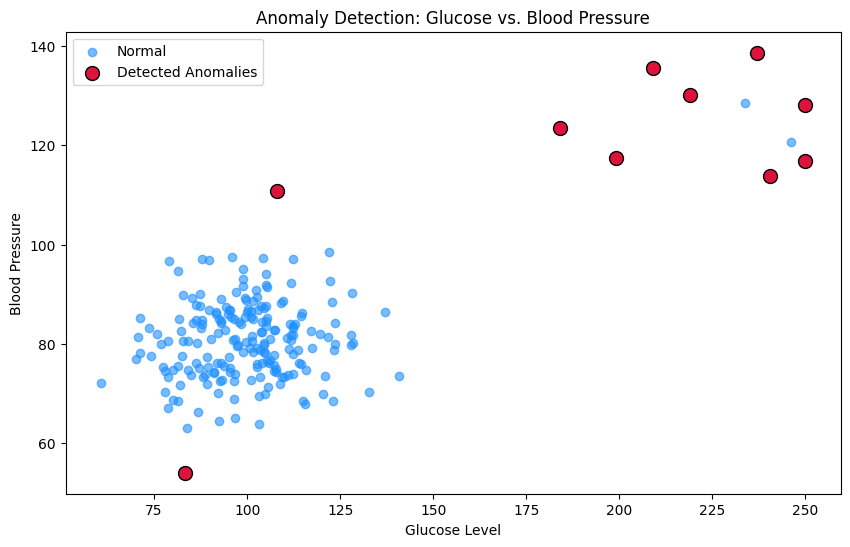

Detected Anomalies:
        Glucose  BloodPressure  prediction
9    108.138401     110.821852          -1
62    83.404975      54.069861          -1
200  209.037365     135.489422          -1
201  199.138495     117.420443          -1
202  183.946285     123.516324          -1


In [7]:
plt.figure(figsize=(10, 6))

# Plot Normal Patients (Blue)
normal = df[df['prediction'] == 1]
plt.scatter(normal['Glucose'], normal['BloodPressure'], c='dodgerblue', alpha=0.6, label='Normal')

# Plot Anomalies (Red)
anomalies = df[df['prediction'] == -1]
plt.scatter(anomalies['Glucose'], anomalies['BloodPressure'], c='crimson', s=100, edgecolors='black', label='Detected Anomalies')

plt.title('Anomaly Detection: Glucose vs. Blood Pressure')
plt.xlabel('Glucose Level')
plt.ylabel('Blood Pressure')
plt.legend()
plt.show()

# Show the actual data points flagged as anomalies
print("Detected Anomalies:")
print(anomalies.head())